# 1. Imports and global settings

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

In [2]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("Available GPUs:", gpus)


from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Reproducibility seed
# Using a fixed seed helps make results more repeatable
SEED = 42

def fix_random_seed(seed=SEED):
    """Fix random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(SEED)

print("Setup complete")

Setup complete


# 2. Data loading

In [4]:
def load_data_pt(path):
    """Load a validation/test split into NumPy arrays."""
    data = torch.load(path, map_location="cpu")

    # Convert [N, H, W] uint8 to [N, H, W, 1] float32.
    images = data["images"].numpy().astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)
    
    # ResNet expects 3-channel inputs, so replicate the grayscale channel.
    images = np.repeat(images, repeats=3, axis=-1)
    
    # Multi-label targets.
    labels = data["labels"].numpy().astype("float32")

    meta = {
        "center_labels": data["center_labels"].numpy().astype("int64"),
        "count_labels": data["count_labels"].numpy().astype("int64"),
        "num_digits": data["num_digits"].numpy().astype("int64"),
        "all_digit_labels": data["all_digit_labels"].numpy().astype("int64"),
        "all_positions": data["all_positions"].numpy().astype("int64"),
        "label_type": data.get("label_type", None),
    }
    return images, labels, meta


class LazyMultiTaskSequence(keras.utils.Sequence):
    """Read memory-mapped .pt training files one batch at a time."""

    def __init__(self, paths, batch_size, shuffle=True):
        super().__init__()
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.stores = [
            torch.load(path, map_location="cpu", mmap=True)
            for path in paths
        ]
        self.sizes = [len(store["images"]) for store in self.stores]
        self.offsets = np.cumsum([0] + self.sizes)
        self.total_size = int(self.offsets[-1])
        self.indices = np.arange(self.total_size)
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(self.total_size / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, batch_index):
        batch_indices = self.indices[
            batch_index * self.batch_size:
            (batch_index + 1) * self.batch_size,
        ]
        image_parts = []
        label_parts = []
        histogram_parts = []
        embedding_target_parts = []

        for store_index, store in enumerate(self.stores):
            start = self.offsets[store_index]
            end = self.offsets[store_index + 1]
            selected = batch_indices[(batch_indices >= start) & (batch_indices < end)] - start
            if len(selected) == 0:
                continue

            selected_tensor = torch.as_tensor(selected, dtype=torch.long)
            images = store["images"].index_select(0, selected_tensor).numpy().astype("float32") / 255.0
            images = np.repeat(images[..., None], repeats=3, axis=-1)
            image_parts.append(images)
            label_parts.append(store["labels"].index_select(0, selected_tensor).numpy().astype("float32"))
            histogram_parts.append(store["count_labels"].index_select(0, selected_tensor).numpy().astype("float32"))
            embedding_target_parts.append(store["count_labels"].index_select(0, selected_tensor).numpy().astype("float32"))

        embedding_targets = np.concatenate(embedding_target_parts, axis=0)
        return np.concatenate(image_parts, axis=0), {
            "multilabel_output": np.concatenate(label_parts, axis=0),
            "histogram_output": np.concatenate(histogram_parts, axis=0),
            "embedding_output": embedding_targets,
        }


In [5]:
def build_histograms(all_digit_labels):
    """Build per-image digit count histograms from padded digit labels."""
    histograms = []
    for sample_labels in all_digit_labels:
        hist = np.zeros(10, dtype=np.float32)
        for d in sample_labels:
            if d >= 0:
                hist[d] += 1
        histograms.append(hist)
    return np.stack(histograms, axis=0).astype(np.float32)

In [6]:
# File paths for train, validation, and test.
train_path = os.path.join("./data/train.pt")
train_generated_path = os.path.join("./data/train_generated.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

BATCH_SIZE = 64

# Keep the large training splits lazy; only validation and test are loaded eagerly
if all(os.path.exists(p) for p in [train_path, train_generated_path, val_path, test_path]):
    train_sequence = LazyMultiTaskSequence(
        [train_path, train_generated_path],
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)

    y_val_hist = build_histograms(meta_val["all_digit_labels"])
    y_test_hist = build_histograms(meta_test["all_digit_labels"])

    print("Data loaded successfully.")
    print("Lazy train samples:", train_sequence.total_size)
    print("Train batches:     ", len(train_sequence))
    print("Val:               ", x_val.shape, y_val.shape, y_val_hist.shape)
    print("Test:              ", x_test.shape, y_test.shape, y_test_hist.shape)
    print("You can now proceed to model training and evaluation.")
else:
    print("Dataset files not found yet.")


Data loaded successfully.
Lazy train samples: 150000
Train batches:      2344
Val:                (10000, 64, 64, 3) (10000, 10) (10000, 10)
Test:               (10000, 64, 64, 3) (10000, 10) (10000, 10)
You can now proceed to model training and evaluation.


# 3. Visualization

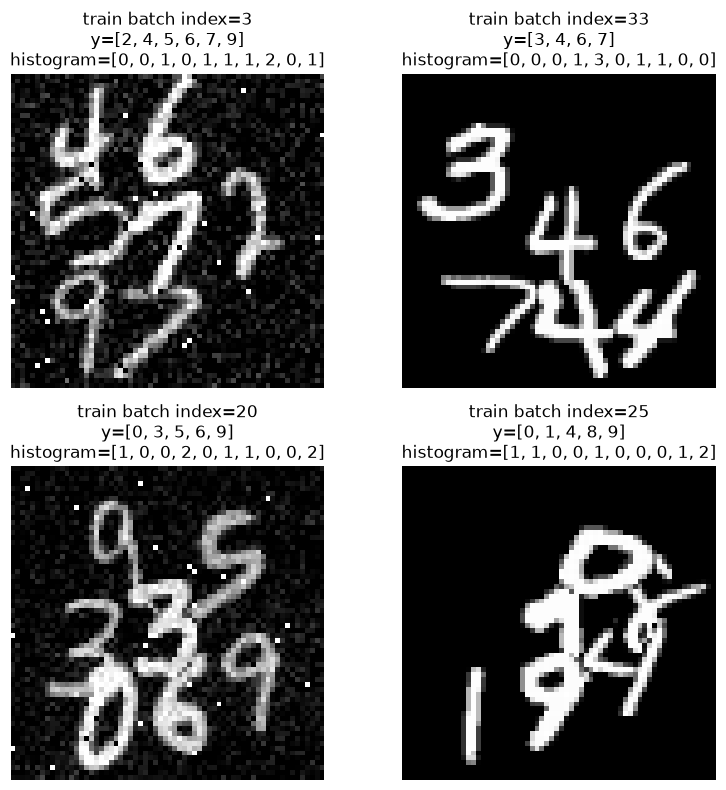

In [7]:
def multihot_to_digits(multihot):
    """Convert a multi-hot vector into a list of digit labels."""
    return np.where(multihot >= 0.5)[0].tolist()


def visualize_train_samples(sequence, num_samples=4):
    """Visualize a few training samples from one lazy-loaded batch."""
    images, targets = sequence[0]
    labels = targets["multilabel_output"]
    histograms = targets["histogram_output"]
    num_samples = min(num_samples, len(images))
    indices = np.random.choice(len(images), size=num_samples, replace=False)

    rows = int(np.ceil(num_samples / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(8, 4 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, idx in zip(axes, indices):
        ax.imshow(images[idx].squeeze(), cmap="gray")
        histogram_text = histograms[idx].astype(np.int64).tolist()
        ax.set_title(f"train batch index={idx}"
                     f"\ny={multihot_to_digits(labels[idx])}"
                     f"\nhistogram={histogram_text}")
        ax.axis("off")

    for ax in axes[num_samples:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Visualize training samples without materializing the full training set.
if "train_sequence" in globals():
    visualize_train_samples(train_sequence, num_samples=4)


# 3. Define exact match accuracy metrics:

In [8]:
def exact_match_accuracy(y_true, y_pred):
    """
    Exact-match accuracy for multi-label classification.

    Steps:
    1. Convert predicted probabilities to binary labels using a threshold.
    2. Compare the whole predicted vector with the true vector.
    3. Count the sample as correct only if every label matches.

    This metric is strict but useful.
    """
    y_pred_binary = tf.cast(y_pred >= 0.5, tf.float32)

    # For each sample, check whether all 10 labels are correct.
    matches = tf.reduce_all(tf.equal(y_true, y_pred_binary), axis=1)

    return tf.reduce_mean(tf.cast(matches, tf.float32))

# 4. Build the ResNet-18 model

In [9]:
MAX_DROP_PATH = 0.2
USE_STOCHASTIC_DEPTH = True


def build_efficientnet_b3_model(input_shape=(64, 64, 3)):
    """Build a randomly initialized EfficientNet-B3 multi-task model."""
    inputs = keras.Input(shape=input_shape)

    # The lazy loader emits [0, 1], while EfficientNet expects [0, 255].
    efficientnet_inputs = layers.Rescaling(
        255.0,
        name="efficientnet_input_rescaling",
    )(inputs)

    # EfficientNet applies stochastic depth internally through drop_connect_rate.
    backbone = keras.applications.EfficientNetB3(
        include_top=False,
        weights=None,
        input_tensor=efficientnet_inputs,
        pooling=None,
    )
    gap = layers.GlobalAveragePooling2D(name="avg_pool")(backbone.output)

    # This branch regularizes semantic similarity independently of fc1.
    embedding = layers.Dense(128, use_bias=False, name="embedding")(gap)
    embedding_output = layers.UnitNormalization(axis=-1, name="embedding_output")(embedding)

    x = layers.Dense(512, activation="relu", name="fc1")(gap)
    x = layers.Dropout(0.3, name="dropout")(x)
    multilabel_output = layers.Dense(10, activation="sigmoid", name="multilabel_output")(x)
    histogram_output = layers.Dense(10, activation="linear", name="histogram_output")(x)

    return keras.Model(
        inputs=inputs,
        outputs={
            "multilabel_output": multilabel_output,
            "histogram_output": histogram_output,
            "embedding_output": embedding_output,
        },
        name="multi_task_efficientnet_b3",
    )


In [10]:
# Build the model
INPUT_SHAPE = (64, 64, 3)
model = build_efficientnet_b3_model(input_shape=INPUT_SHAPE)


In [11]:
class BatchSimilarityMAE(keras.losses.Loss):
    """Match pairwise histogram similarity to pairwise embedding similarity."""

    def call(self, y_true, y_pred):
        digit_totals = tf.reduce_sum(y_true, axis=-1, keepdims=True)
        hist_norm = y_true / tf.maximum(digit_totals, tf.keras.backend.epsilon())
        hist_norm = tf.math.l2_normalize(hist_norm, axis=-1)
        target_similarity = tf.matmul(hist_norm, hist_norm, transpose_b=True)

        embedding = tf.math.l2_normalize(y_pred, axis=-1)
        predicted_similarity = tf.matmul(embedding, embedding, transpose_b=True)
        predicted_similarity = (predicted_similarity + 1.0) / 2.0

        return tf.reduce_mean(tf.abs(predicted_similarity - target_similarity), axis=1)


# Compile the model with separate losses and metrics for each output.
model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.05,
        momentum=0.9,
        use_ema=True,
        weight_decay=5e-3
    ),
    loss={
        "multilabel_output": keras.losses.BinaryCrossentropy(),
        "histogram_output": keras.losses.MeanAbsoluteError(),
        "embedding_output": BatchSimilarityMAE(name="similarity_loss"),
    },
    loss_weights={
        "multilabel_output": 0.33,
        "histogram_output": 0.33,
        "embedding_output": 0.33,
    },
    metrics={
        "multilabel_output": [
            keras.metrics.BinaryAccuracy(name="binary_accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.MeanMetricWrapper(exact_match_accuracy, name="exact_match_accuracy"),
        ],
        "histogram_output": [
            keras.metrics.MeanAbsoluteError(name="mae"),
        ],
    },
)


In [12]:
class MultiTaskTrainingLogger(keras.callbacks.Callback):
    """Print a compact epoch summary for the two-task training run."""

    def on_train_begin(self, logs=None):
        self.total_epochs = self.params.get("epochs", 0)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        def get_value(key):
            value = logs.get(key, float("nan"))
            return float(value)

        lr = self.model.optimizer.learning_rate
        if hasattr(lr, "numpy"):
            lr = float(lr.numpy())
        else:
            lr = float(tf.keras.backend.get_value(lr))
            
        print("=" * 50)
        print(f"Epoch {epoch + 1}/{self.total_epochs}")
        print("=" * 50)
        print()
        print("Train")
        print(f"  Exact Match  : {get_value('multilabel_output_exact_match_accuracy'):.4f}")
        print(f"  Loss         : {get_value('multilabel_output_loss'):.4f}")
        print(f"  Precision    : {get_value('multilabel_output_precision'):.4f}")
        print(f"  Recall       : {get_value('multilabel_output_recall'):.4f}")
        print()
        print("Validation")
        print(f"  Exact Match  : {get_value('val_multilabel_output_exact_match_accuracy'):.4f}")
        print(f"  Loss         : {get_value('val_multilabel_output_loss'):.4f}")
        print(f"  Precision    : {get_value('val_multilabel_output_precision'):.4f}")
        print(f"  Recall       : {get_value('val_multilabel_output_recall'):.4f}")
        print()
        print("Histogram")
        print(f"  Train Loss: {get_value('histogram_output_loss'):.4f} ")
        print(f"  Val Loss: {get_value('val_histogram_output_loss'):.4f} ")
        print()
        print("Embedding")
        print(f"  Train Loss: {get_value('embedding_output_loss'):.4f} ")
        print(f"  Val Loss: {get_value('val_embedding_output_loss'):.4f} ")
        print()
        print(f"Learning Rate : {lr:.4f}")
        print()


In [13]:
model.summary()

Model: "multi_task_efficientnet_b3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnet_input… │ (None, 64, 64, 3) │          0 │ input_layer[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 64, 64, 3) │          0 │ efficientnet_inp… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 64, 64, 3) │          7 │ rescaling[0][0]   │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 65, 65, 3) │          0 │ normalization[0]… │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 32, 32,    │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 32, 32,    │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 32, 32,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 32, 32,    │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 32, 32,    │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 32, 32,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 32, 32,    │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 32, 32,    │        960 │ block1a_se_excit

 Total params: 11,777,347 (44.93 MB)

 Trainable params: 11,690,044 (44.59 MB)

 Non-trainable params: 87,303 (341.03 KB)

# 5. Train the model

In [14]:
# Training hyperparameters.
BATCH_SIZE = 64
EPOCHS = 200

# Use callbacks to improve training.
callbacks = [
    MultiTaskTrainingLogger(),
    keras.callbacks.EarlyStopping(
        monitor="val_multilabel_output_exact_match_accuracy",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.1,
        patience=10,
        min_lr=1e-5,
        verbose=1
    ),
]


In [15]:
# Train the model.
history = model.fit(
    train_sequence,
    validation_data=(
        x_val,
        {
            "multilabel_output": y_val,
            "histogram_output": y_val_hist,
            "embedding_output": y_val_hist,
        },
    ),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=0,
)


E0000 00:00:1785313347.187625 2125081 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1785313512.814994 2125080 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Epoch 1/200

Train
  Exact Match  : 0.0053
  Loss         : 0.6565
  Precision    : 0.5901
  Recall       : 0.6717

Validation
  Exact Match  : 0.0028
  Loss         : 0.6771
  Precision    : 0.5672
  Recall       : 0.7756

Histogram
  Train Loss: 0.6166 
  Val Loss: 0.6382 

Embedding
  Train Loss: 0.1648 
  Val Loss: 0.4444 

Learning Rate : 0.0500

Epoch 2/200

Train
  Exact Match  : 0.0676
  Loss         : 0.4768
  Precision    : 0.7752
  Recall       : 0.7516

Validation
  Exact Match  : 0.0363
  Loss         : 0.5172
  Precision    : 0.7191
  Recall       : 0.7776

Histogram
  Train Loss: 0.4470 
  Val Loss: 0.4820 

Embedding
  Train Loss: 0.1448 
  Val Loss: 0.2626 

Learning Rate : 0.0500

Epoch 3/200

Train
  Exact Match  : 0.3375
  Loss         : 0.2812
  Precision    : 0.9131
  Recall       : 0.8668

Validation
  Exact Match  : 0.3028
  Loss         : 0.3082
  Precision    : 0.8849
  Recall       : 0.8785

Histogram
  Train Loss: 0.2979 
  Val Loss: 0.3206 

Embedding
  Tra

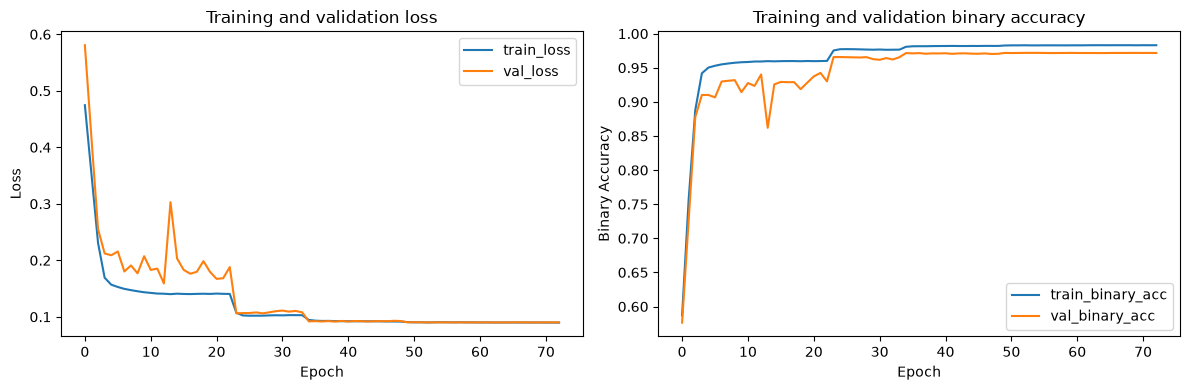

In [16]:
# Plot training history if available.

if "history" in globals():
    plt.figure(figsize=(12, 4))

    # Loss curve.
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()

    # Binary accuracy curve.
    plt.subplot(1, 2, 2)
    plt.plot(history.history["multilabel_output_binary_accuracy"], label="train_binary_acc")
    plt.plot(history.history["val_multilabel_output_binary_accuracy"], label="val_binary_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Accuracy")
    plt.title("Training and validation binary accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No training history found.")

In [17]:
# Evaluate the model on the test set.
results = model.evaluate(
    x_test,
    {
        "multilabel_output": y_test,
        "histogram_output": y_test_hist,
        "embedding_output": y_test_hist,
    },
    verbose=1,
)

# print("\\nTest results:")
# for name, value in zip(model.metrics_names, results):
#     print(f"{name}: {value:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - embedding_output_loss: 0.0810 - histogram_output_loss: 0.0944 - histogram_output_mae: 0.0944 - loss: 0.0881 - multilabel_output_binary_accuracy: 0.9728 - multilabel_output_exact_match_accuracy: 0.7863 - multilabel_output_loss: 0.0916 - multilabel_output_precision: 0.9807 - multilabel_output_recall: 0.9666


# 7. Visualize predictions

In [18]:
# Prediction helper functions
PREDICTION_THRESHOLD=0.5
def probs_to_digits(probs, threshold=PREDICTION_THRESHOLD):
    """Convert prediction probabilities into a list of predicted digits."""
    return np.where(probs >= threshold)[0].tolist()

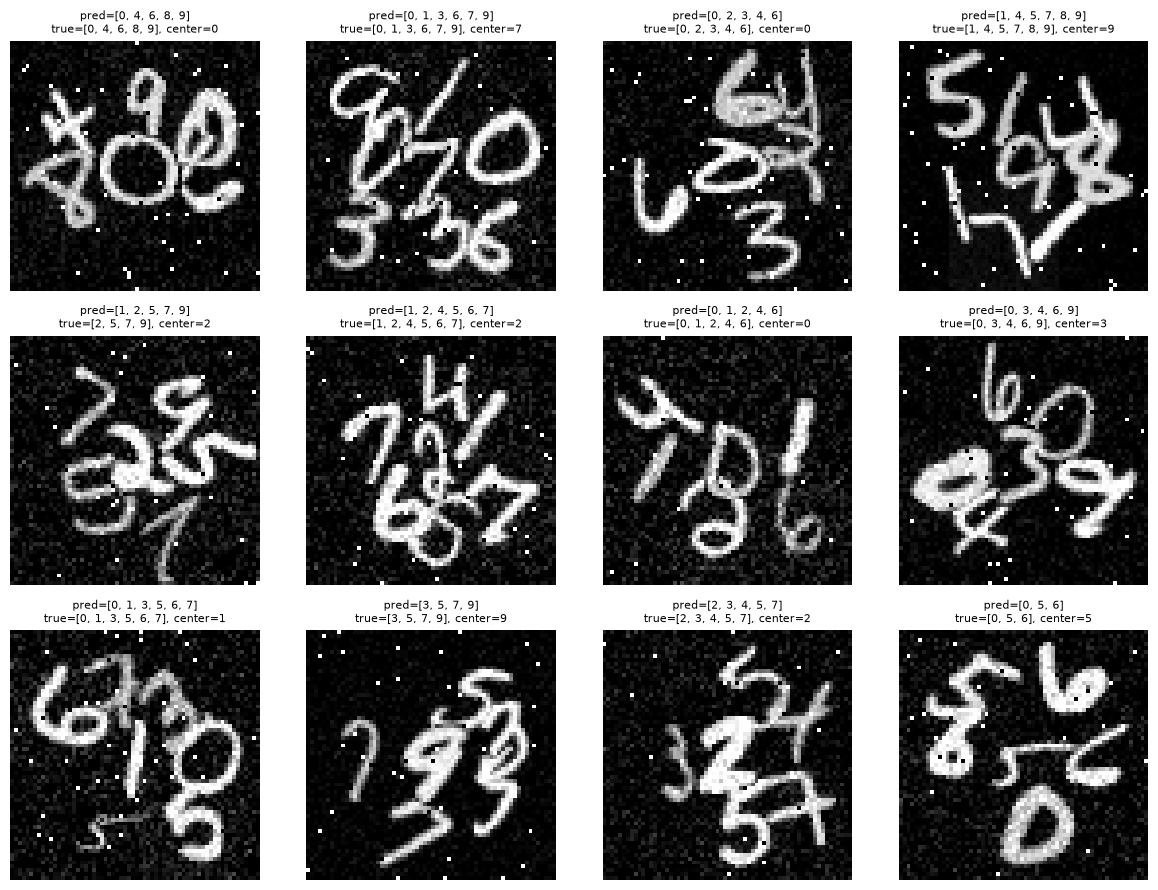

In [19]:
# Visualize several test predictions.

if "model" in globals() and "x_test" in globals():
    indices = np.random.choice(len(x_test), size=12, replace=False)
    preds = model.predict(x_test[indices], verbose=0)
    probs = preds["multilabel_output"]

    plt.figure(figsize=(12, 9))

    for i, idx in enumerate(indices):
        true_digits = multihot_to_digits(y_test[idx])
        pred_digits = probs_to_digits(probs[i], threshold=PREDICTION_THRESHOLD)
        center_label = meta_test["center_labels"][idx]

        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"pred={pred_digits}\n"
            f"true={true_digits}, center={center_label}",
            fontsize=8,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Model or test data not available.")

In [ ]:

# Inspect one test prediction in detail.
idx = 0
preds = model.predict(x_test[idx:idx + 1], verbose=0)
prob = preds["multilabel_output"][0]

print("True digits:", multihot_to_digits(y_test[idx]))
print("Predicted digits:", probs_to_digits(prob))
print("Center label:", meta_test["center_labels"][idx])
print()

print("Prediction probabilities:")
for digit, p in enumerate(prob):
    print(f"digit {digit}: {p:.4f}")

True digits: [2, 3, 5, 7, 9]
Predicted digits: [2, 3, 5, 7, 9]
Center label: 7

Prediction probabilities:
digit 0: 0.0269
digit 1: 0.0410
digit 2: 0.9616
digit 3: 0.9891
digit 4: 0.0359
digit 5: 0.9616
digit 6: 0.0311
digit 7: 1.0000
digit 8: 0.0276
digit 9: 0.9795


: 

In [ ]:
# Exit kernel
import os
os.kill(os.getpid(), 9)